# Hogg, Bovy, Lang (2010) — *Fitting a model to data*: urađene vežbe

Ovaj notebook prati rad [arXiv:1008.4686](https://arxiv.org/abs/1008.4686) i dokument sa objašnjenjima na srpskom.
Vežbe su grupisane **po sekcijama rada**. Prve tri su iste kao u radu (Vežbe 1–3); ostale pokrivaju ono što rad traži u sekcijama 3–8. Za tačan tekst svake vežbe pogledaj sam rad.

**Kako da koristiš notebook**
- Pokreći ćelije redom, odozgo nadole (`Shift + Enter`). Kasnije ćelije koriste promenljive iz ranijih.
- Svaka sekcija počinje **podsetnikom** (🔁) šta je šta, a u kodu su komentari na srpskom.
- Potrebne biblioteke: `numpy`, `scipy`, `matplotlib`. Sve ostalo (pa i MCMC) napisano je ručno da vidiš kako radi.

**Mapa notebook-a**
| Deo | Sekcija rada | Šta radiš |
|---|---|---|
| 0 | — | Podaci (Tabela 1) i pomoćne funkcije |
| 1 | Sekcija 1 | Vežbe 1–3: najmanji kvadrati, linija i parabola |
| 2 | Sekcija 2 | Verodostojnost i χ² — ista stvar |
| 3 | Sekcija 3 | Autlajeri: sigma clipping vs. mešavinski model + MCMC |
| 4 | Sekcija 4 | Nesigurnost: kovarijansa, bootstrap, jackknife, posterior |
| 5 | Sekcija 6 | χ² test i nepoznate greške |
| 6 | Sekcija 7 | Greške po x i y (elipse, ugao θ) |
| 7 | Sekcija 8 | Intrinzično rasipanje V |
| 8 | — | Kratak rezime i veza sa PINN-om |

## 0. Podaci i pomoćne funkcije

🔁 **Podsetnik**
- Svaka tačka ima: `x`, `y`, grešku po y (`sigma_y`), grešku po x (`sigma_x`) i korelaciju grešaka `rho_xy` (broj od −1 do 1).
- **Prve 4 tačke su namerno loše (autlajeri).** Rad ih koristi da pokaže kako standardni fit "puca".
- `sigma_x` i `rho_xy` se koriste tek u delu 6 (sekcija 7 rada).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(42)          # da rezultati budu isti svaki put kad pokreneš
plt.rcParams["figure.figsize"] = (7, 4.5)

# Tabela 1 iz rada: ID, x, y, sigma_y, sigma_x, rho_xy
podaci = np.array([
    [ 1, 201, 592, 61,  9, -0.84],
    [ 2, 244, 401, 25,  4,  0.31],
    [ 3,  47, 583, 38, 11,  0.64],
    [ 4, 287, 402, 15,  7, -0.27],
    [ 5, 203, 495, 21,  5, -0.33],
    [ 6,  58, 173, 15,  9,  0.67],
    [ 7, 210, 479, 27,  4, -0.02],
    [ 8, 202, 504, 14,  4, -0.05],
    [ 9, 198, 510, 30, 11, -0.84],
    [10, 158, 416, 16,  7, -0.69],
    [11, 165, 393, 14,  5,  0.30],
    [12, 201, 442, 25,  5, -0.46],
    [13, 157, 317, 52,  5, -0.03],
    [14, 131, 311, 16,  6,  0.50],
    [15, 166, 400, 34,  6,  0.73],
    [16, 160, 337, 31,  5, -0.52],
    [17, 186, 423, 42,  9,  0.90],
    [18, 125, 334, 26,  8,  0.40],
    [19, 218, 533, 16,  6, -0.78],
    [20, 146, 344, 22,  5, -0.56],
])
ID, x, y, sy, sx, rxy = podaci.T

# Dva skupa koja se stalno koriste:
dobre = slice(4, 20)   # tačke 5–20 (bez autlajera)
sve   = slice(0, 20)   # svih 20 tačaka

print("Broj tačaka:", len(x))

Broj tačaka: 20


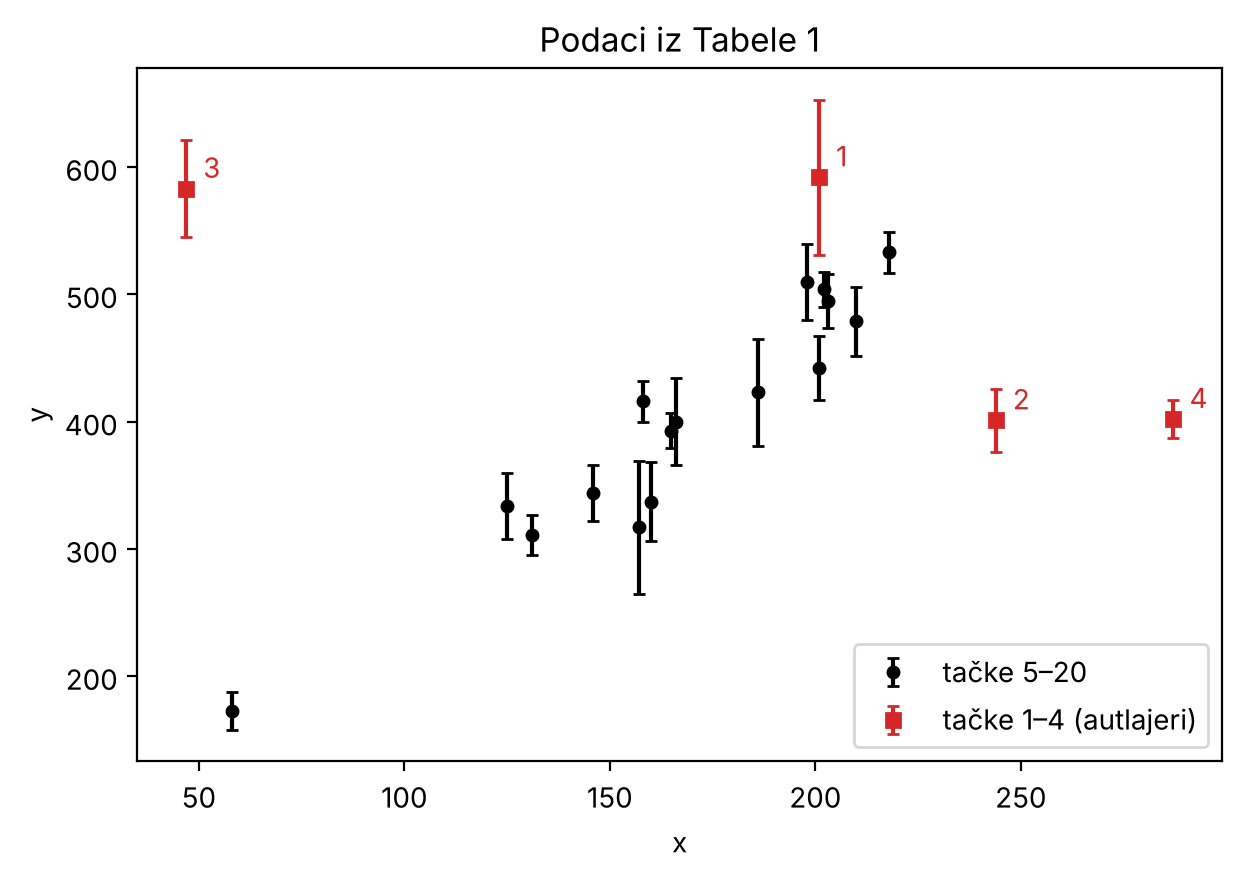

In [2]:
def nacrtaj_podatke(ax=None, oznaci_autlajere=True):
    # Crta tačke sa greškama po y. Autlajere (1–4) boji crveno.
    ax = ax or plt.gca()
    ax.errorbar(x[dobre], y[dobre], yerr=sy[dobre], fmt="o", color="k", ms=4, capsize=2, label="tačke 5–20")
    if oznaci_autlajere:
        ax.errorbar(x[:4], y[:4], yerr=sy[:4], fmt="s", color="tab:red", ms=5, capsize=2, label="tačke 1–4 (autlajeri)")
        for i in range(4):
            ax.annotate(str(int(ID[i])), (x[i], y[i]), textcoords="offset points", xytext=(6, 4), color="tab:red")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    return ax

nacrtaj_podatke(); plt.legend(); plt.title("Podaci iz Tabele 1"); plt.show()

## 1. Sekcija 1 — Najmanji kvadrati (Vežbe 1–3)

🔁 **Podsetnik**
- Model: $y = m x + b$. Parametri: **m** (nagib) i **b** (odsečak).
- Matrice: **Y** (kolona y vrednosti), **A** (matrica dizajna: kolona jedinica i kolona x), **C** (greške $\sigma_y^2$ na dijagonali).
- Rešenje: $X = [A^\top C^{-1} A]^{-1} A^\top C^{-1} Y$, a nesigurnost parametara: $[A^\top C^{-1} A]^{-1}$.
- $C^{-1}$ = **težine**: precizna tačka (mala σ) više "vuče" liniju.
- Važi **samo** ako: greške samo po y, Gausove, poznate, nezavisne, bez autlajera.

In [3]:
def najmanji_kvadrati(x, y, sy, stepen=1):
    # Ponderisani najmanji kvadrati za polinom zadatog stepena.
    # Vraća: parametre [b, m, (q)], njihove greške, matricu kovarijanse i chi^2.
    A = np.vstack([x**k for k in range(stepen + 1)]).T   # kolone: 1, x, x^2, ...
    Cinv = np.diag(1.0 / sy**2)                            # C^{-1} = težine
    cov = np.linalg.inv(A.T @ Cinv @ A)                    # [A^T C^-1 A]^-1
    X = cov @ (A.T @ Cinv @ y)                             # najbolji parametri
    chi2 = np.sum(((y - A @ X) / sy) ** 2)                 # ukupni ponderisani promašaj
    return X, np.sqrt(np.diag(cov)), cov, chi2

### Vežba 1 — linija kroz tačke 5–20 (samo σ_y)
Očekivani rezultat iz rada: $y = (2{,}24 \pm 0{,}11)\,x + (34 \pm 18)$.

In [4]:
X1, e1, cov1, chi2_1 = najmanji_kvadrati(x[dobre], y[dobre], sy[dobre])
b1, m1 = X1
print(f"Vežba 1:  y = ({m1:.2f} ± {e1[1]:.2f}) x + ({b1:.0f} ± {e1[0]:.0f})")
print(f"chi^2 = {chi2_1:.1f}  za N-K = {16-2} stepeni slobode")

Vežba 1:  y = (2.24 ± 0.11) x + (34 ± 18)
chi^2 = 18.7  za N-K = 14 stepeni slobode


### Vežba 2 — linija kroz svih 20 tačaka
Očekivano iz rada: $y = (1{,}08 \pm 0{,}08)\,x + (213 \pm 14)$. **Pogledaj kako 4 autlajera prepolove nagib**, a greška postane još manja (fit je pogrešan *i* samouveren).

Vežba 2:  y = (1.08 ± 0.08) x + (213 ± 14)
chi^2 = 290.0  za N-K = 18 stepeni slobode  <-- ogromno!


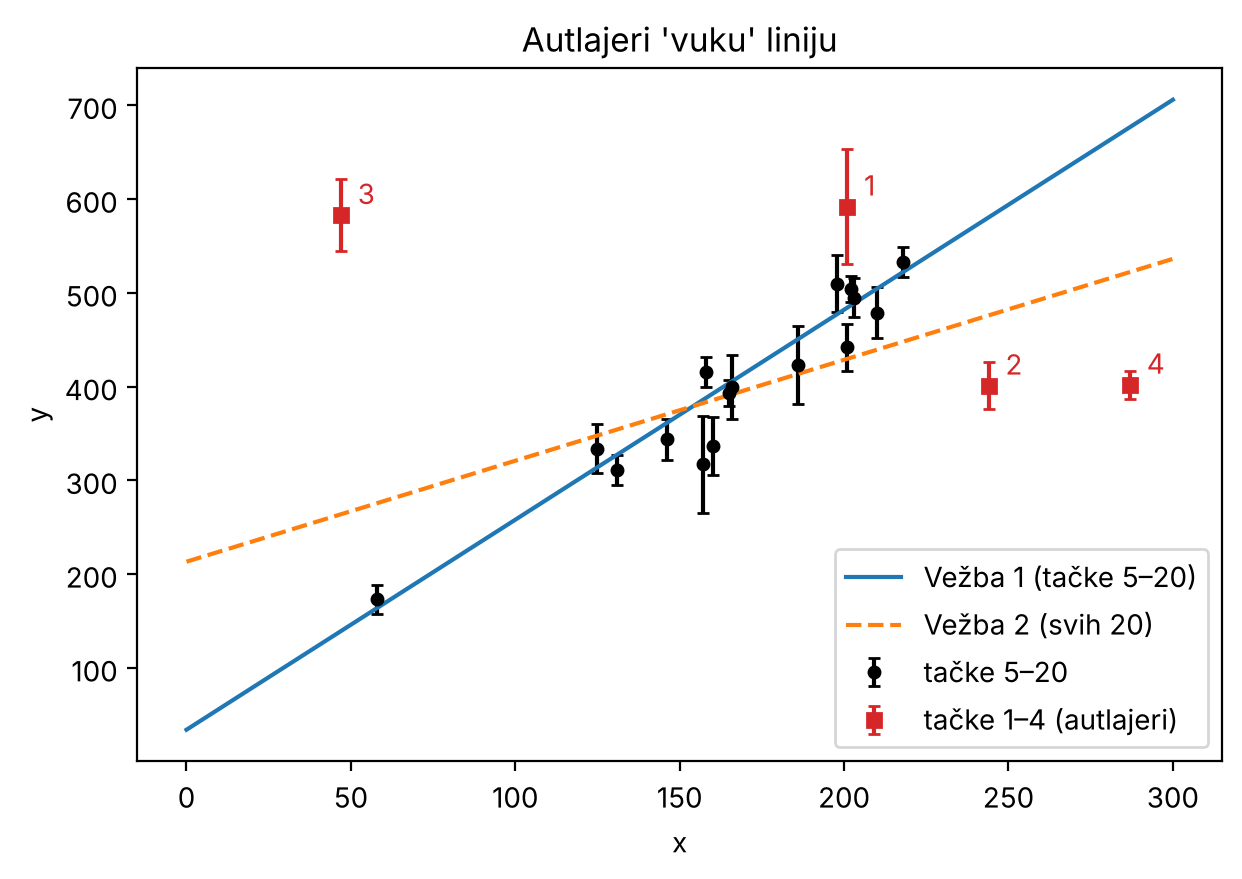

In [5]:
X2, e2, cov2, chi2_2 = najmanji_kvadrati(x, y, sy)
b2, m2 = X2
print(f"Vežba 2:  y = ({m2:.2f} ± {e2[1]:.2f}) x + ({b2:.0f} ± {e2[0]:.0f})")
print(f"chi^2 = {chi2_2:.1f}  za N-K = {20-2} stepeni slobode  <-- ogromno!")

xx = np.linspace(0, 300, 100)
nacrtaj_podatke()
plt.plot(xx, m1*xx + b1, label="Vežba 1 (tačke 5–20)")
plt.plot(xx, m2*xx + b2, "--", label="Vežba 2 (svih 20)")
plt.legend(); plt.title("Autlajeri 'vuku' liniju"); plt.show()

### Vežba 3 — parabola kroz tačke 5–20
Model $y = q x^2 + m x + b$. Ista formula, samo dodaš kolonu $x^2$ u **A**. Očekivano iz rada: $q = 0{,}0023 \pm 0{,}0020$, $m = 1{,}60 \pm 0{,}58$, $b = 72 \pm 38$.

💡 **Zapamti:** metoda je "linearna" kad je model linearan **po parametrima**, čak i ako je kriva.

Vežba 3:  y = (0.0023 ± 0.0020) x^2 + (1.60 ± 0.58) x + (73 ± 39)
chi^2 = 17.4
q je 1.1 sigma od nule -> podaci ne pokazuju jasnu zakrivljenost


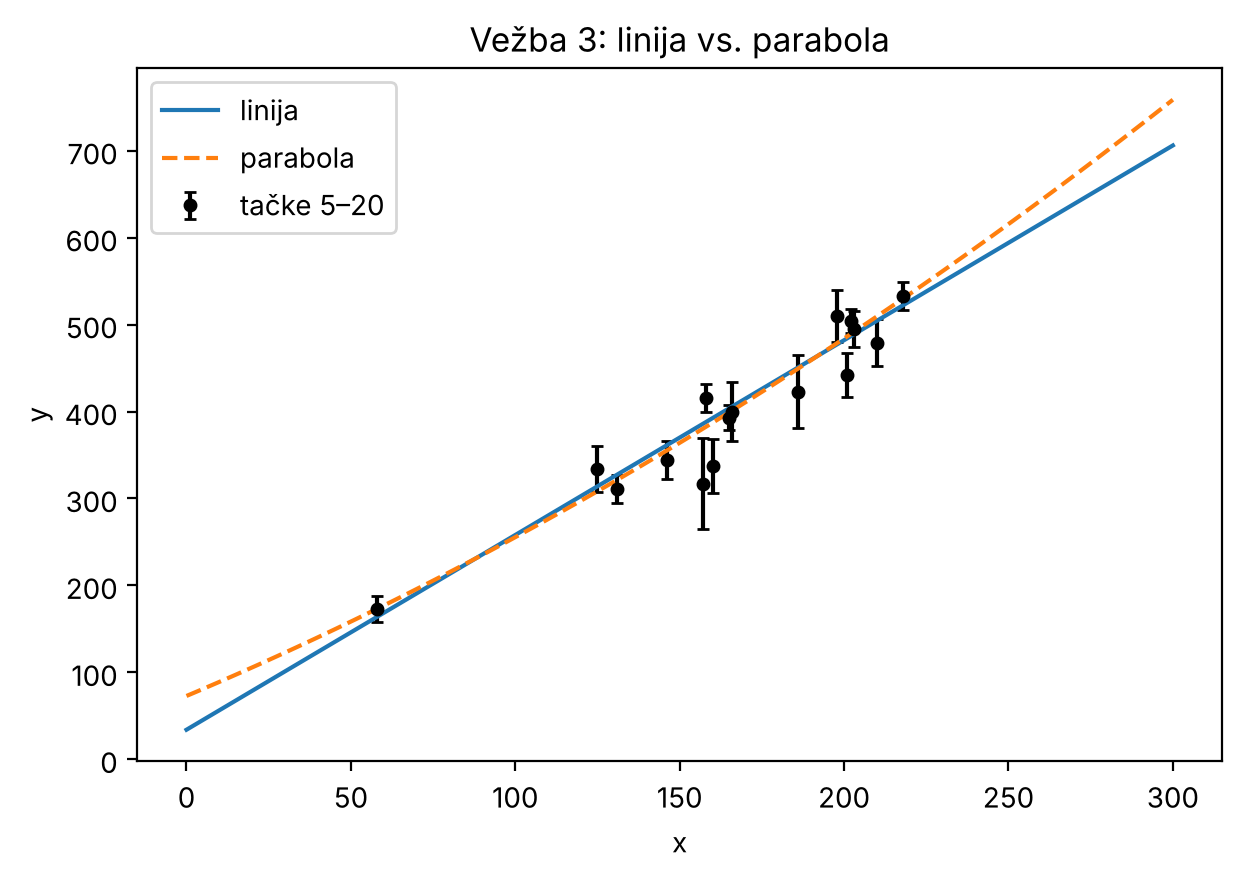

In [6]:
X3, e3, cov3, chi2_3 = najmanji_kvadrati(x[dobre], y[dobre], sy[dobre], stepen=2)
b3, m3, q3 = X3
print(f"Vežba 3:  y = ({q3:.4f} ± {e3[2]:.4f}) x^2 + ({m3:.2f} ± {e3[1]:.2f}) x + ({b3:.0f} ± {e3[0]:.0f})")
print(f"chi^2 = {chi2_3:.1f}")
print(f"q je {abs(q3)/e3[2]:.1f} sigma od nule -> podaci ne pokazuju jasnu zakrivljenost")

nacrtaj_podatke(oznaci_autlajere=False)
plt.plot(xx, m1*xx + b1, label="linija")
plt.plot(xx, q3*xx**2 + m3*xx + b3, "--", label="parabola")
plt.legend(); plt.title("Vežba 3: linija vs. parabola"); plt.show()

## 2. Sekcija 2 — Verodostojnost i χ² su ista stvar

🔁 **Podsetnik**
- **Verodostojnost (likelihood)** $\mathcal{L}$ = verovatnoća podataka ako su parametri takvi i takvi: $p(\text{podaci} \mid m, b)$.
- Za Gausove greške: $\ln \mathcal{L} = K - \tfrac{1}{2}\chi^2$. **Maksimum** $\ln\mathcal{L}$ = **minimum** $\chi^2$.
- U ML-u: MSE loss = Gausov šum; cross-entropy = drugi generativni model. Loss je uvek $-\ln \mathcal{L}$ nekog modela.

Ovde to proveravamo numerički: minimizujemo $-\ln\mathcal{L}$ optimizatorom (kao gradijentni spust u ML-u) i dobijamo isto što i formula iz Vežbe 1.

In [7]:
def neg_ln_L_gaus(p, x, y, sy):
    # -ln L za liniju sa Gausovim greškama po y (uključujući konstantu).
    b, m = p
    r = y - (m*x + b)                      # rezidual = promašaj
    return 0.5*np.sum(r**2/sy**2 + np.log(2*np.pi*sy**2))

res = minimize(neg_ln_L_gaus, x0=[0, 1], args=(x[dobre], y[dobre], sy[dobre]))
print("Optimizator (max likelihood): b = %.2f, m = %.4f" % tuple(res.x))
print("Formula (najmanji kvadrati):  b = %.2f, m = %.4f" % (b1, m1))

Optimizator (max likelihood): b = 34.05, m = 2.2399
Formula (najmanji kvadrati):  b = 34.05, m = 2.2399


## 3. Sekcija 3 — Autlajeri

🔁 **Podsetnik**
- **Sigma clipping**: fituj → izbaci tačke dalje od n·σ → ponovi. Proizvoljno (koliko n? koliko ponavljanja?).
- **Mešavinski model**: svaka tačka je *dobra* (sa verovatnoćom $1-P_b$, dolazi iz linije) ili *loša* (sa verovatnoćom $P_b$, dolazi iz širokog Gausa sa sredinom $Y_b$ i varijansom $V_b$).
- **Parametri smetnje** (nuisance): $P_b, Y_b, V_b$ — potrebni modelu, ali nas ne zanimaju.
- **Marginalizacija** = "saberi" posterior po parametrima smetnje. Sa MCMC uzorcima: samo ignoriši te kolone.
- **MCMC (Metropolis–Hastings)**: šetnja kroz prostor parametara koja provodi vreme srazmerno posterioru.

### 3a. Sigma clipping (da vidiš zašto ga autori ne vole)

In [8]:
def sigma_clipping(x, y, sy, prag=3.0, max_iter=10):
    maska = np.ones(len(x), bool)              # True = tačka je zadržana
    for it in range(max_iter):
        (b, m), *_ = najmanji_kvadrati(x[maska], y[maska], sy[maska])
        odstupanje = np.abs(y - (m*x + b)) / sy   # u jedinicama sigme
        nova = odstupanje < prag
        if np.array_equal(nova, maska):
            break
        maska = nova
    return m, b, maska

for prag in [1.0, 1.5, 2.0, 3.0, 5.0, 8.0, 10.0]:
    m_c, b_c, maska = sigma_clipping(x, y, sy, prag)
    izbaceni = ID[~maska].astype(int).tolist()
    print(f"prag {prag}σ: m = {m_c:.2f}, b = {b_c:.0f}, izbačene tačke: {izbaceni}")
print("\n-> Za prag 2–5σ izgleda dobro, ali za 1–1.5σ izbaci i dobre tačke, a za 8–10σ zadrži autlajere.")
print("   Rezultat zavisi od proizvoljnog izbora praga i ne daje verovatnoće. Zato autori preporučuju mešavinski model.")

prag 1.0σ: m = 1.70, b = 110, izbačene tačke: [1, 2, 3, 4, 5, 6, 8, 9, 10, 13, 14, 16, 19]
prag 1.5σ: m = 1.96, b = 61, izbačene tačke: [1, 2, 3, 4, 5, 8, 9, 10, 19]
prag 2.0σ: m = 2.25, b = 33, izbačene tačke: [2, 3, 4]
prag 3.0σ: m = 2.25, b = 33, izbačene tačke: [2, 3, 4]
prag 5.0σ: m = 2.25, b = 33, izbačene tačke: [2, 3, 4]
prag 8.0σ: m = 2.02, b = 65, izbačene tačke: [3, 4]
prag 10.0σ: m = 1.08, b = 213, izbačene tačke: []

-> Za prag 2–5σ izgleda dobro, ali za 1–1.5σ izbaci i dobre tačke, a za 8–10σ zadrži autlajere.
   Rezultat zavisi od proizvoljnog izbora praga i ne daje verovatnoće. Zato autori preporučuju mešavinski model.


### 3b. Mešavinski model — verodostojnost

$$
\mathcal{L} \propto \prod_i \left[ \frac{1-P_b}{\sqrt{2\pi\sigma_{yi}^2}} e^{-\frac{(y_i - m x_i - b)^2}{2\sigma_{yi}^2}} + \frac{P_b}{\sqrt{2\pi(V_b+\sigma_{yi}^2)}} e^{-\frac{(y_i - Y_b)^2}{2(V_b+\sigma_{yi}^2)}} \right]
$$

Parametre držimo kao vektor `p = [b, m, Pb, Yb, lnVb]`. Za $V_b$ koristimo logaritam ($\ln V_b$) jer $V_b$ mora biti pozitivno, a ovako optimizator i MCMC ne mogu da ga "guraju" u negativne vrednosti.

In [9]:
def delovi_mesavine(p, x, y, sy):
    # Vraća dva sabirka za svaku tačku: (dobra, loša).
    b, m, Pb, Yb, lnVb = p
    Vb = np.exp(lnVb)
    dobra = (1 - Pb) * np.exp(-(y - m*x - b)**2 / (2*sy**2)) / np.sqrt(2*np.pi*sy**2)
    losa  = Pb * np.exp(-(y - Yb)**2 / (2*(Vb + sy**2))) / np.sqrt(2*np.pi*(Vb + sy**2))
    return dobra, losa

def ln_posterior_mesavina(p, x, y, sy):
    # ln posterior = ln prior + ln L.  Prior: ravan, uz uslove 0 < Pb < 1 i razumne granice.
    b, m, Pb, Yb, lnVb = p
    if not (0 < Pb < 1) or not (-5 < lnVb < 20):
        return -np.inf                          # nemoguće vrednosti -> verovatnoća 0
    dobra, losa = delovi_mesavine(p, x, y, sy)
    return np.sum(np.log(dobra + losa))

# Prvo nađemo najbolju tačku (MAP) optimizatorom — dobar start za MCMC
start = [b1, m1, 0.2, np.mean(y), np.log(np.var(y))]
res = minimize(lambda p: -ln_posterior_mesavina(p, x, y, sy), start, method="Nelder-Mead",
               options={"maxiter": 20000, "xatol": 1e-6, "fatol": 1e-8})
p_map = res.x
print("MAP: b = %.1f, m = %.3f, Pb = %.2f, Yb = %.0f, sqrt(Vb) = %.0f"
      % (p_map[0], p_map[1], p_map[2], p_map[3], np.sqrt(np.exp(p_map[4]))))

MAP: b = 32.0, m = 2.259, Pb = 0.26, Yb = 447, sqrt(Vb) = 71


### 3c. MCMC — Metropolis–Hastings, napisan ručno

🔁 **Algoritam** (isti kao u radu):
1. Kreni od neke tačke `p`.
2. Predloži novu tačku: `p_novo = p + mali slučajan korak`.
3. Izračunaj odnos posteriora; ako je `ln(u) < ln_post(p_novo) - ln_post(p)` za slučajno `u ∈ (0,1)`, pređi u `p_novo`.
4. Zapiši gde si (i kad ostaneš u mestu!). Ponovi mnogo puta.

💡 U praksi se koristi biblioteka **emcee**, ali ručno se bolje vidi kako radi.

In [10]:
def metropolis_hastings(ln_post, p0, koraci, n_iter=50000, burn_in=5000, args=()):
    p = np.array(p0, float)
    lp = ln_post(p, *args)
    lanac = np.empty((n_iter, len(p)))
    prihvaceno = 0
    for i in range(n_iter):
        p_novo = p + koraci * np.random.randn(len(p))   # predlog: Gausov korak
        lp_novo = ln_post(p_novo, *args)
        if np.log(np.random.rand()) < lp_novo - lp:      # pravilo prihvatanja
            p, lp = p_novo, lp_novo
            prihvaceno += 1
        lanac[i] = p
    print(f"Udeo prihvaćenih koraka: {prihvaceno/n_iter:.2f}  (dobro je oko 0.2–0.5)")
    return lanac[burn_in:]      # odbacujemo početak ("burn-in") dok se lanac ne smiri

koraci = np.array([8.0, 0.04, 0.05, 25.0, 0.3])   # veličina koraka za [b, m, Pb, Yb, lnVb]
lanac = metropolis_hastings(ln_posterior_mesavina, p_map, koraci, args=(x, y, sy))

Udeo prihvaćenih koraka: 0.44  (dobro je oko 0.2–0.5)


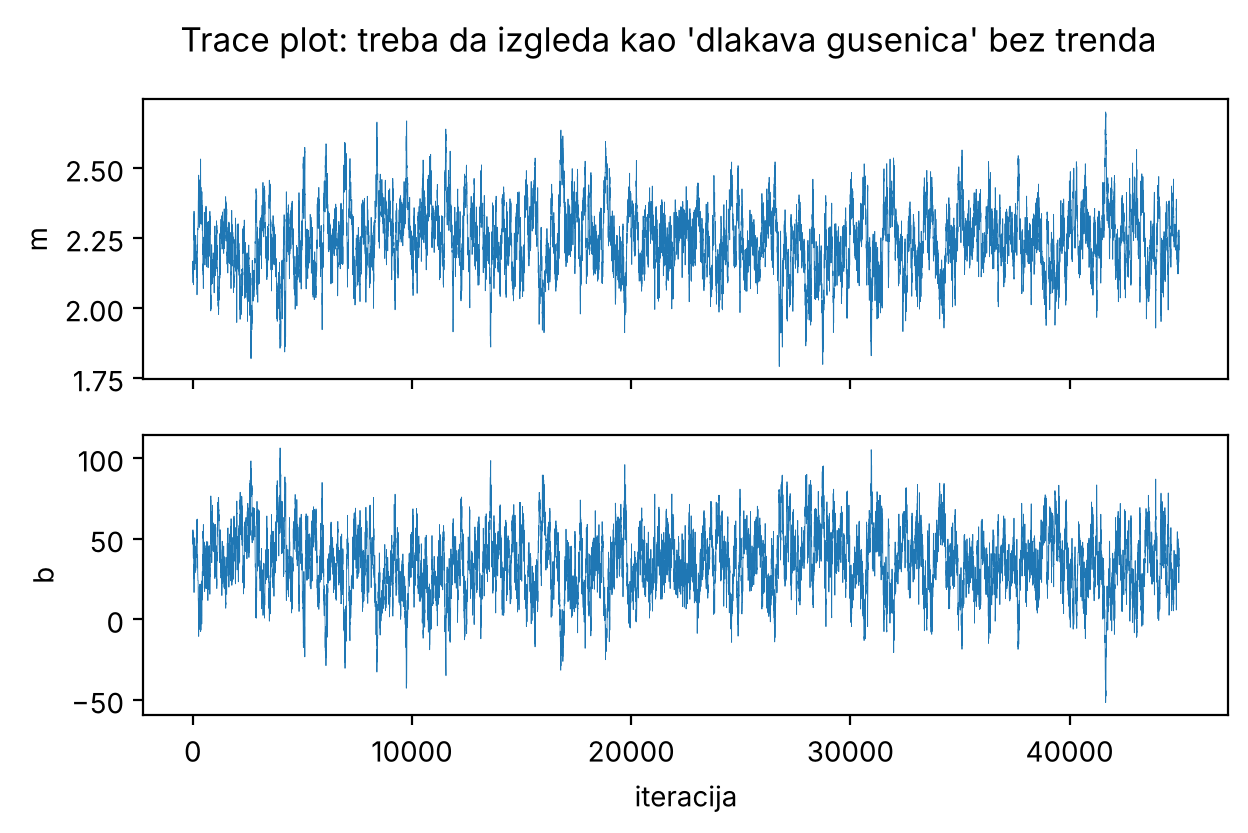

In [11]:
# Provera da li se lanac "smirio": trace plot (vrednost parametra kroz iteracije)
fig, axs = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
axs[0].plot(lanac[:, 1], lw=0.3); axs[0].set_ylabel("m")
axs[1].plot(lanac[:, 0], lw=0.3); axs[1].set_ylabel("b"); axs[1].set_xlabel("iteracija")
plt.suptitle("Trace plot: treba da izgleda kao 'dlakava gusenica' bez trenda"); plt.show()

### 3d. Marginalizacija = ignorišemo kolone P_b, Y_b, V_b

Marginalizovan posterior:  m = 2.24 ± 0.12,  b = 35 ± 19
Poređenje, Vežba 1 (bez autlajera, ručno):  m = 2.24 ± 0.11,  b = 34 ± 18


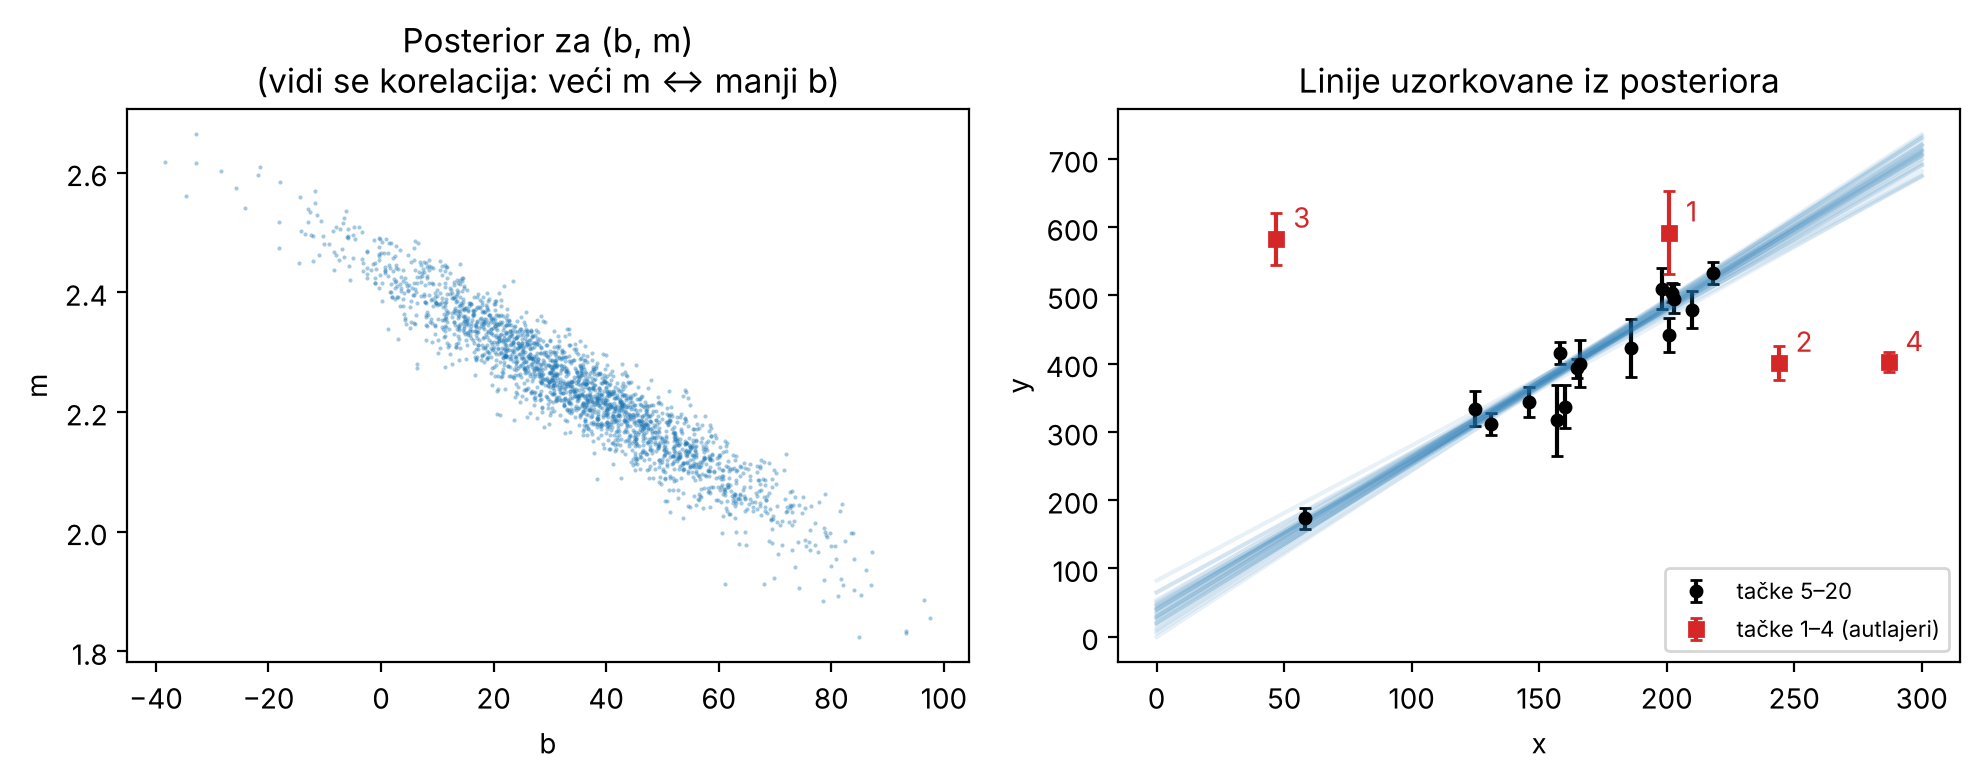

In [12]:
m_uz, b_uz = lanac[:, 1], lanac[:, 0]       # samo kolone m i b -> marginalizovano!
print(f"Marginalizovan posterior:  m = {np.mean(m_uz):.2f} ± {np.std(m_uz):.2f},  b = {np.mean(b_uz):.0f} ± {np.std(b_uz):.0f}")
print(f"Poređenje, Vežba 1 (bez autlajera, ručno):  m = {m1:.2f} ± {e1[1]:.2f},  b = {b1:.0f} ± {e1[0]:.0f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(b_uz[::20], m_uz[::20], ".", ms=1, alpha=0.4)
axs[0].set_xlabel("b"); axs[0].set_ylabel("m"); axs[0].set_title("Posterior za (b, m)\n(vidi se korelacija: veći m ↔ manji b)")
nacrtaj_podatke(axs[1])
for k in np.random.randint(0, len(lanac), 30):           # 30 linija iz posteriora
    axs[1].plot(xx, lanac[k, 1]*xx + lanac[k, 0], color="tab:blue", alpha=0.1)
axs[1].set_title("Linije uzorkovane iz posteriora"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3e. Verovatnoća da je svaka tačka loša
Za svaku tačku: $P(\text{loša}) = \dfrac{\text{loša}}{\text{dobra} + \text{loša}}$, uprosečeno preko MCMC uzoraka (to je opet marginalizacija!).

In [13]:
uzorci = lanac[np.random.randint(0, len(lanac), 2000)]
p_losa = np.mean([delovi_mesavine(p, x, y, sy)[1] / np.sum(delovi_mesavine(p, x, y, sy), axis=0)
                  for p in uzorci], axis=0)
for i in range(20):
    traka = "█" * int(round(p_losa[i]*20))
    print(f"tačka {int(ID[i]):2d}: {p_losa[i]:5.2f}  {traka}")
print("\n-> Model je SAM našao tačke 2, 3, 4. Tačka 1 ima veliku grešku (σ=61), pa je dvosmislena.")

tačka  1:  0.28  ██████
tačka  2:  1.00  ████████████████████
tačka  3:  1.00  ████████████████████
tačka  4:  1.00  ████████████████████
tačka  5:  0.09  ██
tačka  6:  0.01  
tačka  7:  0.15  ███
tačka  8:  0.13  ███
tačka  9:  0.15  ███
tačka 10:  0.24  █████
tačka 11:  0.08  ██
tačka 12:  0.32  ██████
tačka 13:  0.18  ████
tačka 14:  0.05  █
tačka 15:  0.12  ██
tačka 16:  0.25  █████
tačka 17:  0.18  ████
tačka 18:  0.07  █
tačka 19:  0.07  █
tačka 20:  0.07  █

-> Model je SAM našao tačke 2, 3, 4. Tačka 1 ima veliku grešku (σ=61), pa je dvosmislena.


## 4. Sekcija 4 — Nesigurnost najboljih parametara

🔁 **Podsetnik**
- **Kovarijansa** $[A^\top C^{-1}A]^{-1}$: brza, ali tačna samo ako je model tačan.
- **Bootstrap**: izvuci N tačaka *sa vraćanjem*, fituj, ponovi M puta; rasipanje rezultata = greška.
- **Jackknife**: izbaci jednu po jednu tačku; $\sigma_m^2 = \frac{N-1}{N}\sum_j (m_j - \bar m)^2$.
- **Posterior** (MCMC): standardna devijacija uzoraka.

In [14]:
def bootstrap(x, y, sy, M=5000):
    N = len(x); ms = []
    for _ in range(M):
        k = np.random.randint(0, N, N)          # indeksi sa vraćanjem
        ms.append(najmanji_kvadrati(x[k], y[k], sy[k])[0][1])
    return np.std(ms)

def jackknife(x, y, sy):
    N = len(x)
    ms = np.array([najmanji_kvadrati(np.delete(x, j), np.delete(y, j), np.delete(sy, j))[0][1] for j in range(N)])
    return np.sqrt((N - 1) / N * np.sum((ms - ms.mean())**2))

print("Greška nagiba m:")
print(f"{'metoda':<22}{'tačke 5–20':>12}{'svih 20':>12}")
print(f"{'kovarijansa':<22}{e1[1]:>12.3f}{e2[1]:>12.3f}")
print(f"{'bootstrap':<22}{bootstrap(x[dobre], y[dobre], sy[dobre]):>12.3f}{bootstrap(x, y, sy):>12.3f}")
print(f"{'jackknife':<22}{jackknife(x[dobre], y[dobre], sy[dobre]):>12.3f}{jackknife(x, y, sy):>12.3f}")
print(f"{'posterior (mešavina)':<22}{'—':>12}{np.std(m_uz):>12.3f}")
print("\n-> Sa autlajerima kovarijansa kaže ±0.08, a bootstrap/jackknife otkrivaju da je fit nestabilan.")

Greška nagiba m:
metoda                  tačke 5–20     svih 20
kovarijansa                  0.108       0.077


bootstrap                    0.152       0.611
jackknife                    0.166       0.874
posterior (mešavina)             —       0.117

-> Sa autlajerima kovarijansa kaže ±0.08, a bootstrap/jackknife otkrivaju da je fit nestabilan.


## 5. Sekcija 6 — Kvalitet fita i nepoznate greške

🔁 **Podsetnik**
- Ako je model tačan: $\chi^2 \approx (N-K) \pm \sqrt{2(N-K)}$. N = broj tačaka, K = broj parametara.
- χ² ≫ N−K: loš model / potcenjene greške / autlajeri. χ² ≪ N−K: precenjene greške ili overfitting.
- **Nepoznate greške**: σ postaje parametar. Tada u $\ln\mathcal{L}$ **mora** da ostane član $\ln \sigma^2$ (kazna), inače σ → ∞.

In [15]:
for ime, chi2, N, K in [("Vežba 1", chi2_1, 16, 2), ("Vežba 2", chi2_2, 20, 2), ("Vežba 3", chi2_3, 16, 3)]:
    dof = N - K
    z = (chi2 - dof) / np.sqrt(2*dof)
    print(f"{ime}: chi^2 = {chi2:6.1f},  očekivano {dof} ± {np.sqrt(2*dof):.1f}  -> odstupanje {z:+.1f} 'sigma'")

Vežba 1: chi^2 =   18.7,  očekivano 14 ± 5.3  -> odstupanje +0.9 'sigma'
Vežba 2: chi^2 =  290.0,  očekivano 18 ± 6.0  -> odstupanje +45.3 'sigma'
Vežba 3: chi^2 =   17.4,  očekivano 13 ± 5.1  -> odstupanje +0.9 'sigma'


### Nepoznata (ista) greška σ za sve tačke
Pretvaramo se da ne znamo $\sigma_y$ za tačke 5–20 i učimo jedno zajedničko σ iz podataka.

In [16]:
def neg_ln_L_nepoznata_sigma(p, x, y):
    b, m, ln_s = p
    s2 = np.exp(2*ln_s)
    r = y - (m*x + b)
    return 0.5*np.sum(r**2/s2 + np.log(2*np.pi*s2))   # <-- log član je ključan!

res = minimize(neg_ln_L_nepoznata_sigma, [b1, m1, np.log(30)], args=(x[dobre], y[dobre]), method="Nelder-Mead")
b_u, m_u, ln_s = res.x
print(f"Naučeno: m = {m_u:.2f}, b = {b_u:.0f}, sigma = {np.exp(ln_s):.1f}")
print(f"Za poređenje, prosečna prijavljena sigma_y za tačke 5–20: {np.mean(sy[dobre]):.1f}")

# Šta bi se desilo BEZ log člana? Optimizator bi "pobegao" u ogromnu sigmu:
with np.errstate(over="ignore"):
    los = minimize(lambda p: 0.5*np.sum((y[dobre]-p[1]*x[dobre]-p[0])**2/np.exp(2*p[2])),
                   [b1, m1, np.log(30)], method="Nelder-Mead")
print(f"Bez log člana: sigma = {np.exp(los.x[2]):.3g}  <-- besmisleno velika")

Naučeno: m = 2.22, b = 29, sigma = 28.7
Za poređenje, prosečna prijavljena sigma_y za tačke 5–20: 25.1
Bez log člana: sigma = 7.47e+206  <-- besmisleno velika


## 6. Sekcija 7 — Greške i po x i po y

🔁 **Podsetnik**
- Svaka tačka ima matricu $S_i = \begin{bmatrix}\sigma_x^2 & \rho\sigma_x\sigma_y\\ \rho\sigma_x\sigma_y & \sigma_y^2\end{bmatrix}$ — "elipsu nesigurnosti".
- Liniju opisujemo **uglom θ** i rastojanjem $b_\perp = b\cos\theta$ (ne nagibom m, jer m → ∞ za vertikalne linije).
- $\hat v = [-\sin\theta, \cos\theta]$ je vektor normalan na liniju.
- Rastojanje tačke od linije: $\Delta_i = \hat v^\top Z_i - b_\perp$; njegova greška ("senka elipse"): $\Sigma_i^2 = \hat v^\top S_i \hat v$.

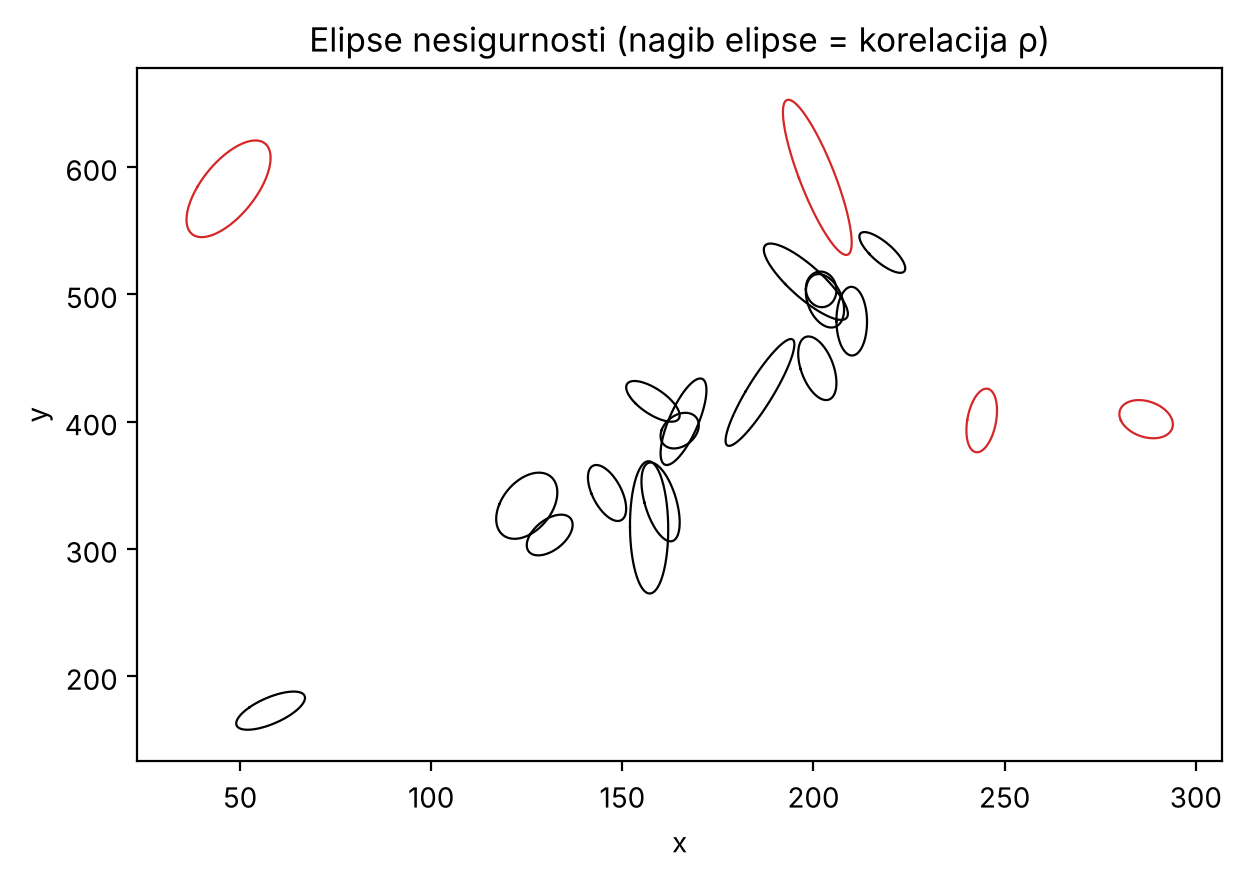

In [17]:
def S_matrice(sx, sy, rxy):
    # Vraća niz 2x2 kovarijansnih matrica, po jednu za svaku tačku.
    sxy = rxy * sx * sy
    return np.array([[[a**2, c], [c, d**2]] for a, d, c in zip(sx, sy, sxy)])

def nacrtaj_elipse(ax, x, y, S, boja="k"):
    # Elipsa 1-sigma za svaku tačku (preko sopstvenih vrednosti matrice S).
    t = np.linspace(0, 2*np.pi, 60)
    krug = np.vstack([np.cos(t), np.sin(t)])
    for xi, yi, Si in zip(x, y, S):
        vr, vek = np.linalg.eigh(Si)
        elipsa = vek @ np.diag(np.sqrt(vr)) @ krug
        ax.plot(xi + elipsa[0], yi + elipsa[1], color=boja, lw=0.8)

S_sve = S_matrice(sx, sy, rxy)
fig, ax = plt.subplots()
nacrtaj_elipse(ax, x[dobre], y[dobre], S_sve[dobre])
nacrtaj_elipse(ax, x[:4], y[:4], S_sve[:4], boja="tab:red")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("Elipse nesigurnosti (nagib elipse = korelacija ρ)")
plt.show()

In [18]:
def ln_L_2d(p, x, y, S, sa_V=False):
    # ln L za liniju sa 2D greškama. p = [theta, b_perp] ili [theta, b_perp, V].
    theta, b_perp = p[0], p[1]
    V = p[2] if sa_V else 0.0
    if V < 0 or not (-np.pi/2 < theta < np.pi/2):
        return -np.inf
    v = np.array([-np.sin(theta), np.cos(theta)])
    Delta = v[0]*x + v[1]*y - b_perp                    # ortogonalno rastojanje
    Sigma2 = np.einsum("i,nij,j->n", v, S, v) + V       # projekcija elipse (+ rasipanje)
    return -0.5*np.sum(Delta**2/Sigma2 + np.log(Sigma2))

def u_m_b(theta, b_perp):
    # Pretvaranje (θ, b_perp) nazad u uobičajene (m, b).
    return np.tan(theta), b_perp/np.cos(theta)

t0 = np.arctan(m1); p0 = [t0, b1*np.cos(t0)]
res = minimize(lambda p: -ln_L_2d(p, x[dobre], y[dobre], S_sve[dobre]), p0, method="Nelder-Mead",
               options={"xatol": 1e-9, "fatol": 1e-10})
m_2d, b_2d = u_m_b(*res.x)
print(f"2D greške, tačke 5–20:  y = {m_2d:.2f} x + {b_2d:.0f}")
print(f"Samo greške po y (Vežba 1): y = {m1:.2f} x + {b1:.0f}")

2D greške, tačke 5–20:  y = 2.26 x + 26
Samo greške po y (Vežba 1): y = 2.24 x + 34


## 7. Sekcija 8 — Intrinzično rasipanje

🔁 **Podsetnik**
- **Intrinzično rasipanje V**: prirodna "debljina" veze, nije greška instrumenta.
- Dodaje se gresci svake tačke: $\Sigma_i^2 = \hat v^\top S_i \hat v + V$.
- Rasipanje i greške merenja se "menjaju": ako potceniš greške, model će lažno naći rasipanje.

Pravimo MCMC za $(\theta, b_\perp, V)$ sa ravnim priorom za $V \ge 0$.

Udeo prihvaćenih koraka: 0.47  (dobro je oko 0.2–0.5)
sqrt(V): medijana 6.1, 95% gornja granica 12.9


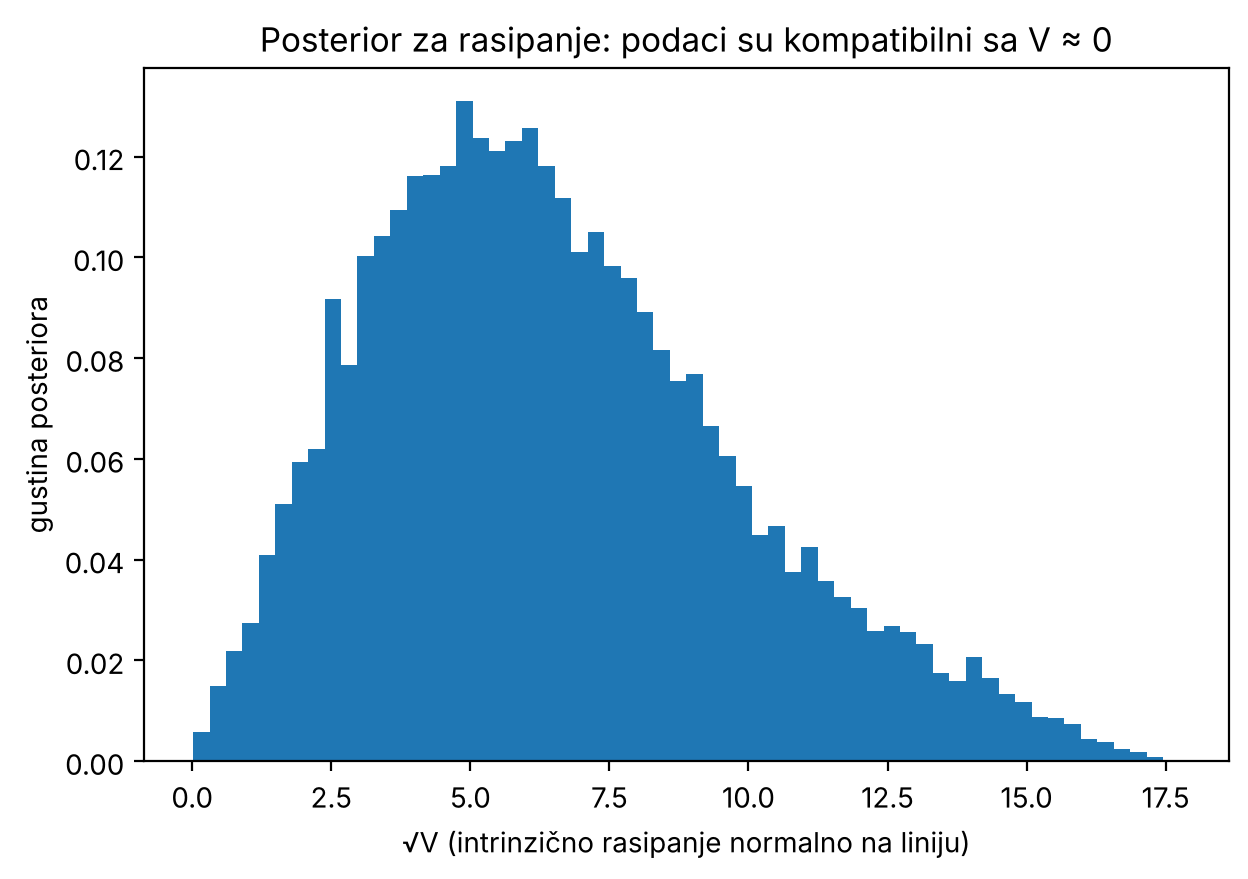

In [19]:
def ln_post_V(p, x, y, S):
    return ln_L_2d(p, x, y, S, sa_V=True)

p0 = [res.x[0], res.x[1], 10.0]
lanac_V = metropolis_hastings(ln_post_V, p0, np.array([0.01, 3.0, 15.0]), n_iter=40000,
                              args=(x[dobre], y[dobre], S_sve[dobre]))
sqrtV = np.sqrt(lanac_V[:, 2])
print(f"sqrt(V): medijana {np.median(sqrtV):.1f}, 95% gornja granica {np.percentile(sqrtV, 95):.1f}")

plt.hist(sqrtV, bins=60, density=True)
plt.xlabel("√V (intrinzično rasipanje normalno na liniju)"); plt.ylabel("gustina posteriora")
plt.title("Posterior za rasipanje: podaci su kompatibilni sa V ≈ 0"); plt.show()

In [20]:
# Lekcija o zameni grešaka i rasipanja: ignorišemo greške po x (stavimo σ_x = 0).
S_bez_x = S_matrice(np.zeros_like(sx), sy, np.zeros_like(rxy))
lanac_V2 = metropolis_hastings(ln_post_V, p0, np.array([0.01, 3.0, 15.0]), n_iter=40000,
                               args=(x[dobre], y[dobre], S_bez_x[dobre]))
print(f"Sa σ_x:     medijana √V = {np.median(np.sqrt(lanac_V[:, 2])):.1f}")
print(f"Bez σ_x:    medijana √V = {np.median(np.sqrt(lanac_V2[:, 2])):.1f}")
print("-> Kad 'zaboraviš' deo grešaka merenja, model ih delom proglasi intrinzičnim rasipanjem.")

Udeo prihvaćenih koraka: 0.48  (dobro je oko 0.2–0.5)
Sa σ_x:     medijana √V = 6.1
Bez σ_x:    medijana √V = 7.4
-> Kad 'zaboraviš' deo grešaka merenja, model ih delom proglasi intrinzičnim rasipanjem.


## 8. Rezime i veza sa PINN-om

| Pojam iz rada | Gde je u notebook-u | U PINN-u |
|---|---|---|
| χ² / −ln L | `najmanji_kvadrati`, `neg_ln_L_gaus` | deo loss-a za podatke (ponderisani MSE) |
| težine 1/σ² | `Cinv` | delite kvadrate grešaka sa σᵢ² ako merenja nisu jednako precizna |
| prior | uslovi u `ln_posterior_mesavina` | fizički zakon u loss-u, regularizacija |
| mešavinski model | deo 3 | robustan loss za loše tačke (kosmički zraci, loša kalibracija) |
| MCMC / posterior | `metropolis_hastings` | Bajesovski PINN, ansambli |
| ln σ² kazna | deo 5 | učenje težina između delova loss-a |

**Šta dalje možeš sama da probaš**
1. Zameni ručni MCMC bibliotekom `emcee` (`pip install emcee`) i uporedi rezultate.
2. U delu 3 promeni prior za $P_b$ (npr. ograniči na < 0.1) i vidi kako se menja rezultat.
3. Napravi sopstvene sintetičke podatke (generativni model!) sa poznatim m i b i proveri da li ih metode pronalaze.